# Euclid forced photometry with Rubin

This notebook demonstrate the forced photometry for the Rubin data/ 

The user must have the access to the Rubin Science Platform (RSP; [data.lsst.cloud](https://data.lsst.cloud)), in order to generae the RSP API token for downloading the science data and PSF in this notebook. 
The rest of the pipeline are the same as the ground-based pipeline ([DR1 ground-based notebook](04_ground_based_forced_photometry.ipynb).)

## 1. RSP token and API access

With an RSP account, create a token at [data.lsst.cloud](https://data.lsst.cloud)
under **Settings → Access tokens**, with `read:tap`, `read:image`, and
`exec:notebook`. Paste the complete `gt-<key>.<secret>` token (not just the token key) into the first
code cell. 

[Token guide](https://rsp.lsst.io/guides/auth/creating-user-tokens.html).


In [1]:
# USER SETTINGS — paste your RSP token here for your local test.
RSP_TOKEN = "PASTE YOUR FULL RSP TOKEN HERE"
RSP_BASE_URL = "https://data.lsst.cloud"
RUBIN_COLLECTION = "dp1"
RUBIN_OBJECT_TABLE = "dp1.Object"

DATA_ACCESS = "Q1"             # Euclid: "DR1" or "Q1"; no automatic fallback
RA, DEC = 59.10, -48.73         # Euclid Deep Field South, degrees
SIZE_ARCSEC = 100.0
RUBIN_BANDS = ["u", "g", "r", "i", "z", "y"]
MASK_BAD_PLANES = ("BAD", "SAT", "NO_DATA")  # Coadd baseline; optionally add "INEXACT_PSF".
N_WORKERS =8 


In [2]:
import time
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.nddata import Cutout2D
from IPython.display import Image, display
import euclid_phot as ep
from euclid_phot import ground_based as gb, rubin
from euclid_phot.rubin.plots import PLOT_BANDS, show_catalog_comparisons
from euclid_phot.rubin.compare import compare_catalog
from euclid_phot.units import pixel_scale_arcsec
from euclid_phot.viz import ujy_per_unit

ep.set_data_access(DATA_ACCESS)
DATA_DIR = ep.get_data_dir()
RUBIN_CACHE = ep.config.DEFAULT_DATA_DIR / "rubin"
RUBIN_OUTPUT = ep.config.DEFAULT_DATA_DIR.parent / "output" / "rubin"


In [3]:
client = rubin.RubinClient(
    RSP_TOKEN, cache_dir=RUBIN_CACHE,
    config=rubin.RubinConfig(base_url=RSP_BASE_URL, collection=RUBIN_COLLECTION,
                             object_table=RUBIN_OBJECT_TABLE))
connection = client.check_connection()
columns = client.object_columns()


## 2. Download Rubin data



Download calibrated coadds, variance, masks and WCS through SIA/DataLink/SODA,
and `dp1.Object` measurements through TAP. The science images are background subtracted.

`SIZE_ARCSEC` and `RUBIN_BANDS` select the field and bands;
The images have no added padding. Each band must fit in one coadd patch.

The coadd mask uses `BAD`, `SAT`, `NO_DATA`, plus invalid pixels/variance.
See the [Rubin coadd mask guidance](https://dp1.lsst.io/tutorials/notebook/202/notebook-202-6.html).


In [4]:
downloaded = rubin.download_field(
    client, RA, DEC, SIZE_ARCSEC, bands=RUBIN_BANDS,
    bad_planes=MASK_BAD_PLANES,
)
summary = Table(rows=[
    (band, data.tract, data.patch, data.image.science.shape[1],
     data.image.science.shape[0], float(np.mean(data.image.valid)),
     len(data.catalog), str(data.image_path))
    for band, data in downloaded.items()
], names=("band", "tract", "patch", "nx", "ny", "usable_fraction", "objects", "cached_fits"))


Rubin dp1: downloading u


  patch 2394/25; (500, 500); 100.0% usable pixels; 465 reference objects
Rubin dp1: downloading g


  patch 2394/25; (500, 500); 100.0% usable pixels; 465 reference objects
Rubin dp1: downloading r


  patch 2394/25; (500, 500); 99.9% usable pixels; 465 reference objects
Rubin dp1: downloading i


  patch 2394/25; (500, 500); 99.9% usable pixels; 465 reference objects
Rubin dp1: downloading z


  patch 2394/25; (500, 500); 99.9% usable pixels; 465 reference objects
Rubin dp1: downloading y


  patch 2394/25; (500, 500); 100.0% usable pixels; 465 reference objects


## 3. Rubin PSF

Retrieve the official PSF at the field center.  Note that the official Rubin PSF profiles include negative pixels that is preserved in this notebook. 

In [5]:
official_psfs = rubin.fetch_official_psfs(
    client, RSP_TOKEN, downloaded,
    {band: [[RA, DEC]] for band in RUBIN_BANDS},
)


u: official PSF (1, 33, 33)


g: official PSF (1, 35, 35)


r: official PSF (1, 35, 35)


i: official PSF (1, 35, 35)


z: official PSF (1, 35, 35)


y: official PSF (1, 35, 35)


### A Saved PSF profile check 

Here we show a saved comparison of the PSF vs stellar profiles from a 300″ square sky covering u/g/r/i/z/y. Shading shows the 16–84% range among stars.  


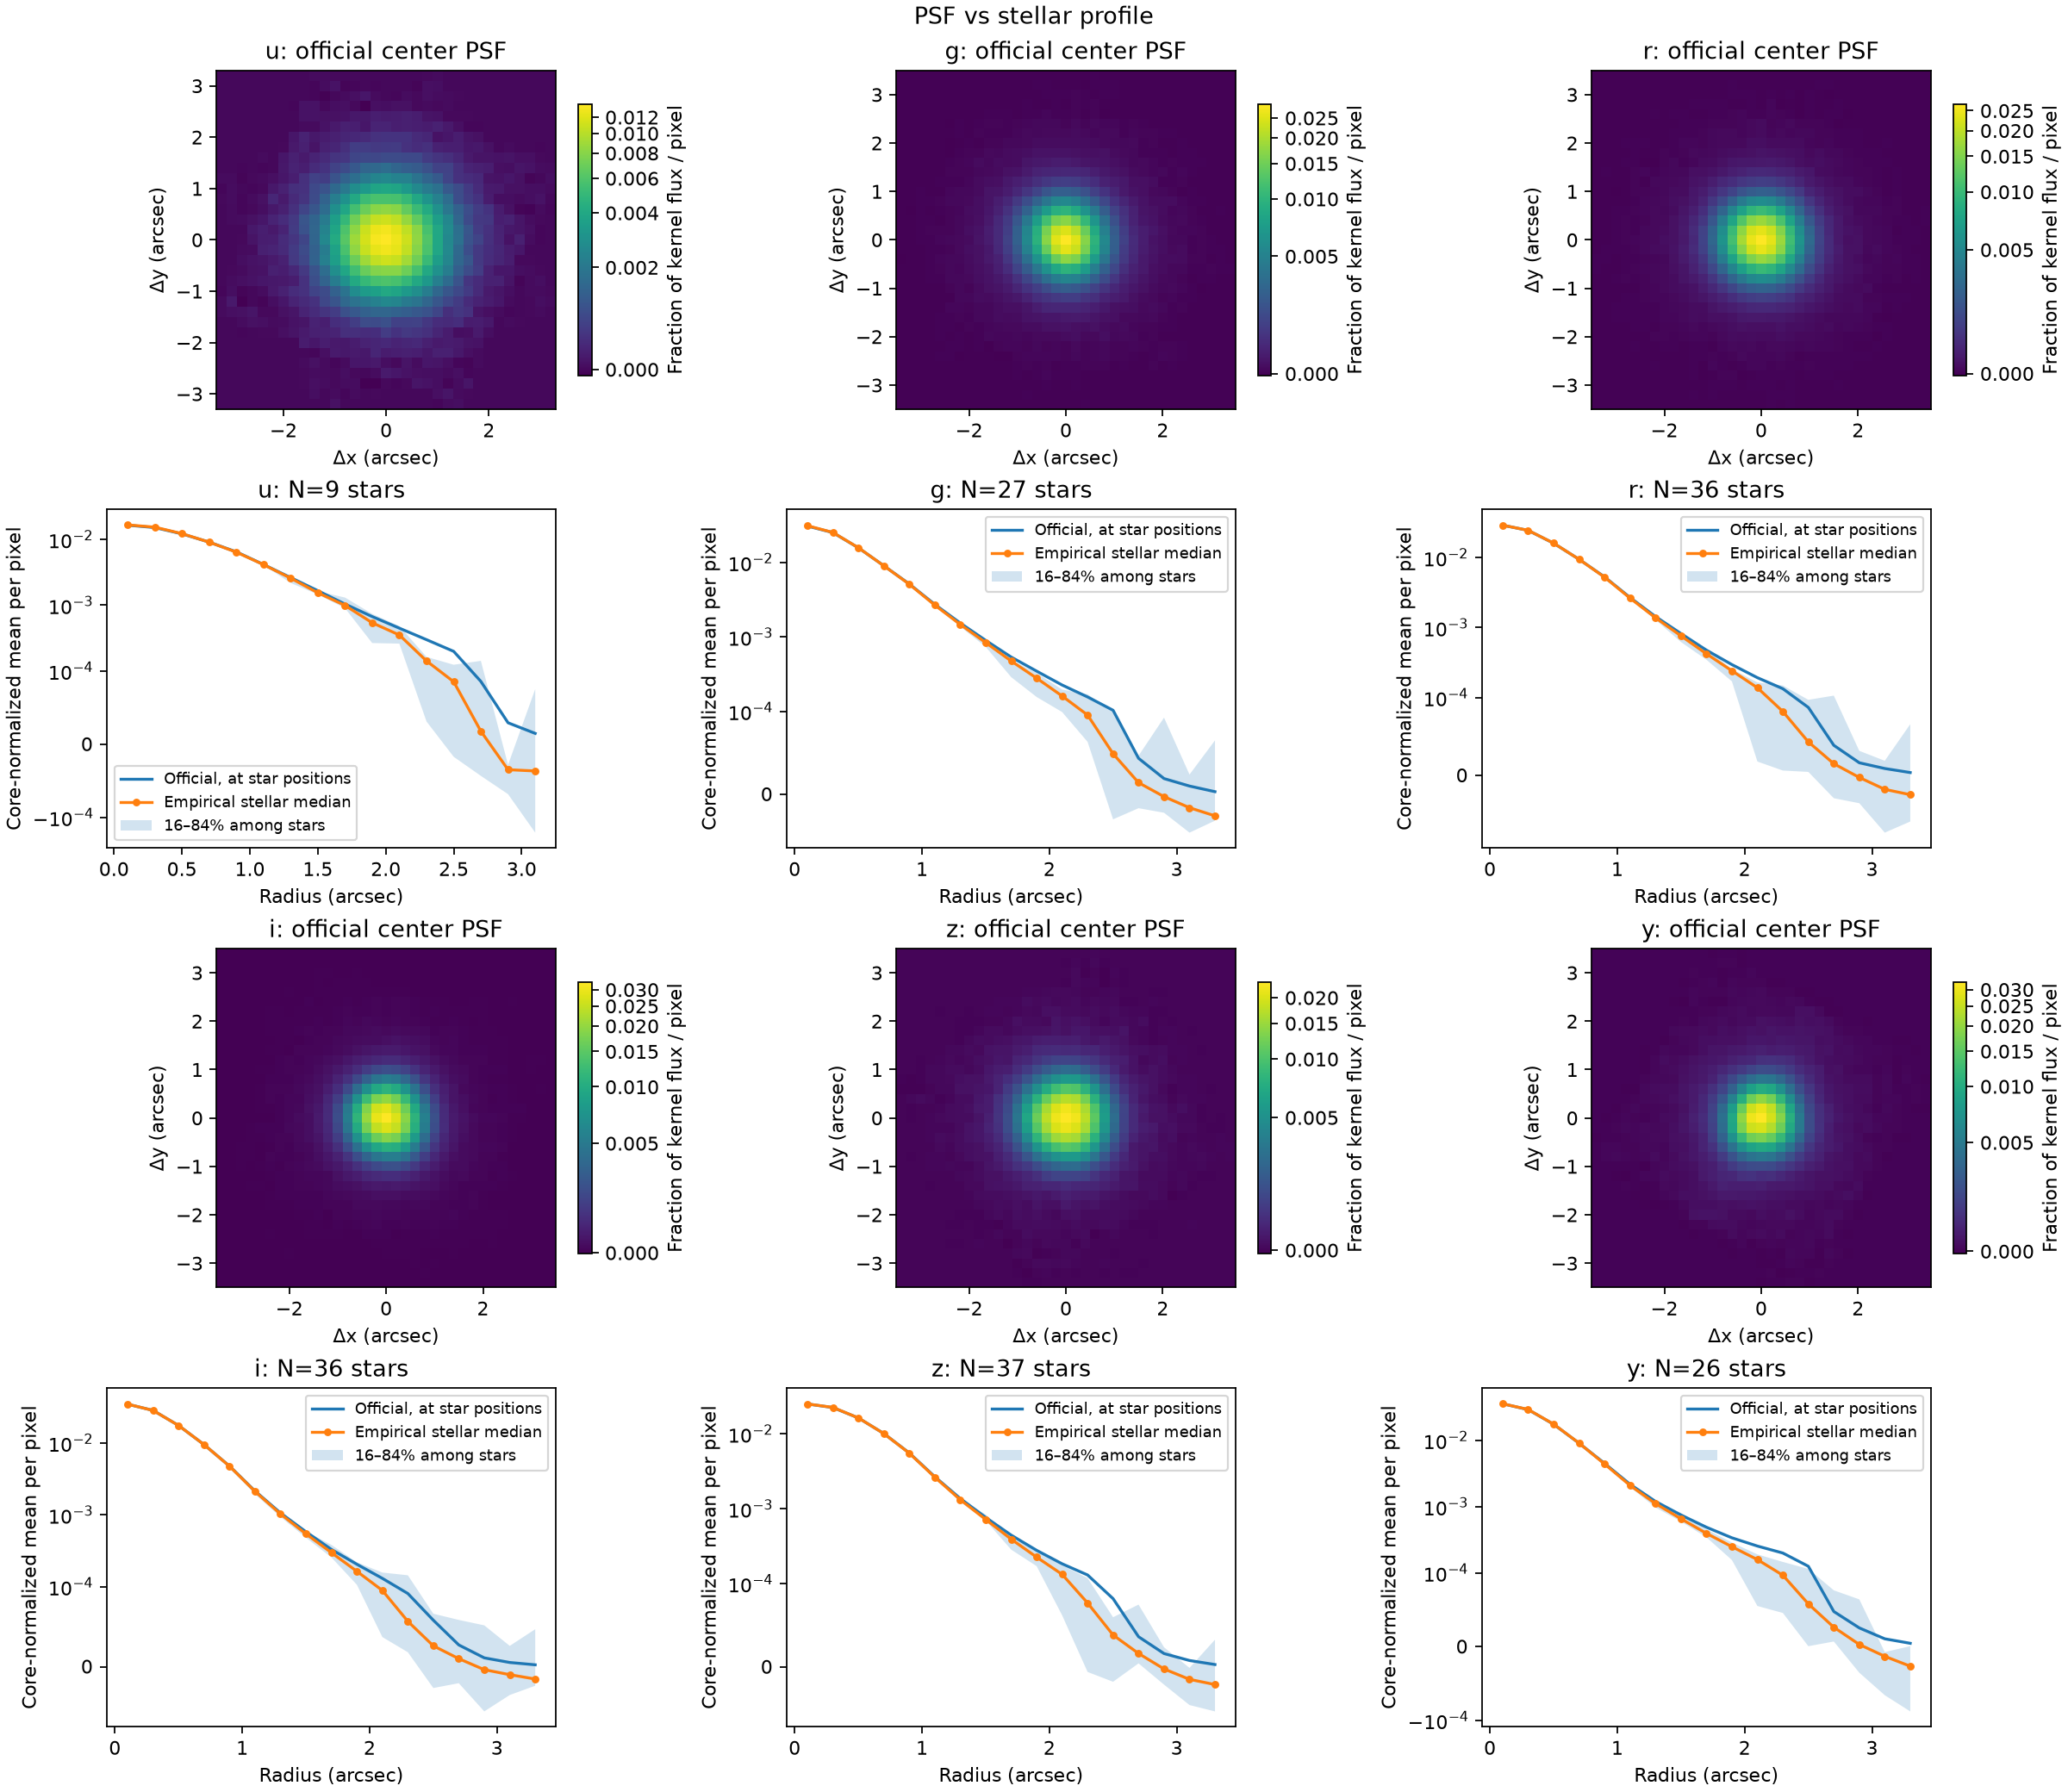

In [6]:
PSF_VALIDATION_DIR = rubin.saved_psf_validation_dir(RUBIN_COLLECTION, RA, DEC)
PSF_DISPLAY_CACHE = RUBIN_OUTPUT / RUBIN_COLLECTION / f"{RA:.5f}_{DEC:+.5f}" / "psf_validation"
selected_bands = tuple(b for b in PLOT_BANDS if b in RUBIN_BANDS)
suffix = "" if selected_bands == PLOT_BANDS else "_" + ("".join(selected_bands) or "none")
cached_png = PSF_DISPLAY_CACHE / f"psf_validation{suffix}.png"
validation_png = cached_png if cached_png.exists() or suffix else PSF_VALIDATION_DIR / "psf_validation.png"
summary_path = PSF_VALIDATION_DIR / "psf_validation_summary.ecsv"
profile_inputs = (summary_path, PSF_VALIDATION_DIR / "psf_validation.png")
updated = max((p.stat().st_mtime for p in profile_inputs if p.exists()), default=0)
if summary_path.exists() and (not validation_png.exists() or validation_png.stat().st_mtime < updated):
    # Display saved profile arrays only; no PSF verification or API calls.
    from euclid_phot.rubin.validation import plot_psf_validation
    validation_png = plot_psf_validation(PSF_VALIDATION_DIR, bands=selected_bands, save_dir=PSF_DISPLAY_CACHE)
if validation_png.exists():
    display(Image(filename=str(validation_png)))
else:
    print("No saved PSF verification for this field. The official PSFs are still available.")


## 4. Euclid-prior forced photometry

The following steps are the same as the ground-based notebook.
Rubin-specific choices are the downloaded image weights, official PSF and WCS.


### 4.1. Build the ground-image inputs

Use `rubin.make_image` as before, with Rubin's calibrated units, baseline mask,
and official signed PSF. Retain the Rubin WCS.


In [7]:
if set(downloaded) != set(official_psfs):
    raise ValueError("Each downloaded band needs its official evaluated PSF.")
ground_inputs = {}
for band in RUBIN_BANDS:
    data, psf = downloaded[band], official_psfs[band]
    if psf.dataset_id != data.dataset_id:
        raise ValueError(f"{band}: science and official PSF datasets differ.")
    if SkyCoord(*psf.positions[0], unit="deg").separation(SkyCoord(RA, DEC, unit="deg")).arcsec > 0.05:
        raise ValueError(f"{band}: official PSF belongs to another sky position.")
    image = data.image
    fitting_rms = np.where(image.valid, image.rms, np.nan)
    ground_inputs[band] = rubin.make_image(
        image.science, fitting_rms, psf.center, image.unit, image.wcs,
        band=band,
    )


### 4.2. Prepare the Euclid scene

Same `gb.prepare_euclid` step as the ground-based notebook. `DATA_ACCESS`
selects DR1 or Q1. The image overview shows science and RMS for VIS and each
Rubin band, using their native pixels.


In [8]:
euclid = gb.prepare_euclid(
    ground_inputs[RUBIN_BANDS[0]].image, DATA_DIR, padding_arcsec=10,
)


MER: querying Euclid for the image footprint


MER: saved mer_catalog_59.1000_-48.7300_130.fits


VIS science/RMS/flag: ready


VIS GRID PSF: ready


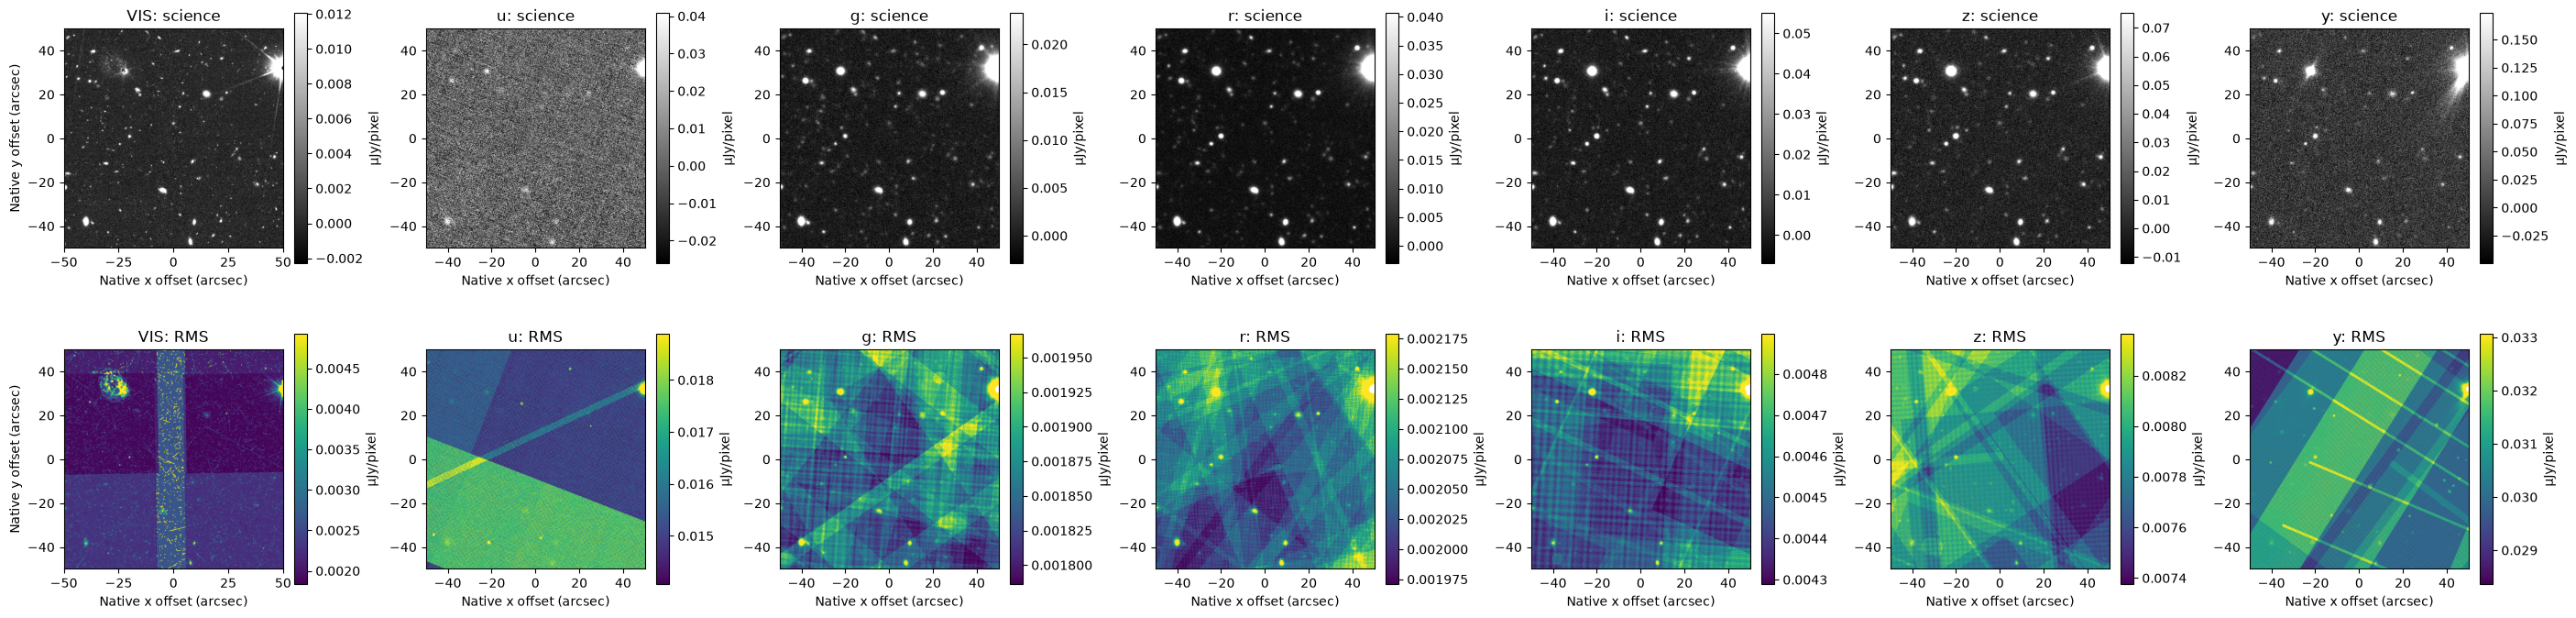

In [9]:
# Display a native-pixel VIS crop of the same requested size, without padding.
center = SkyCoord(RA, DEC, unit="deg")
vis_cut = Cutout2D(euclid.vis_cutout.data, center, SIZE_ARCSEC * u.arcsec,
                  wcs=euclid.vis_cutout.wcs, mode="strict")
vis_factor = ujy_per_unit(euclid.vis_cutout)
vis_science = vis_cut.data * vis_factor
vis_rms = euclid.vis_cutout.rms[vis_cut.slices_original] * vis_factor
panels = [("VIS", vis_science, vis_rms, vis_cut.wcs)]
for band in PLOT_BANDS:
    if band not in RUBIN_BANDS or band not in downloaded:
        panels.append((band, None, None, None))
        continue
    image = downloaded[band].image
    factor = (1 * image.unit).to_value(u.uJy)
    # Only the selected baseline flags and invalid values are excluded.
    panels.append((band, np.where(image.valid, image.science * factor, np.nan),
                   np.where(image.valid, image.rms * factor, np.nan), image.wcs))

fig, axes = plt.subplots(2, len(panels), figsize=(4 * len(panels), 7),
                         squeeze=False, constrained_layout=True)
for col, (band, science, rms, wcs) in enumerate(panels):
    if science is None:
        for ax in axes[:, col]:
            ax.set_axis_off()
        continue
    ny, nx = science.shape
    scale = pixel_scale_arcsec(wcs)
    extent = (-nx * scale / 2, nx * scale / 2, -ny * scale / 2, ny * scale / 2)
    for row, pixels in enumerate((science, rms)):
        lo, hi = np.nanpercentile(pixels, [5, 99] if row == 0 else [1, 99])
        im = axes[row, col].imshow(
            pixels, origin="lower", extent=extent,
            cmap="gray" if row == 0 else "viridis", vmin=lo, vmax=hi,
        )
        axes[row, col].set_title(f"{band}: {'science' if row == 0 else 'RMS'}")
        axes[row, col].set_xlabel("Native x offset (arcsec)")
        if col == 0:
            axes[row, col].set_ylabel("Native y offset (arcsec)")
        fig.colorbar(im, ax=axes[row, col], shrink=0.8, label="µJy/pixel")
overview_path = RUBIN_OUTPUT / RUBIN_COLLECTION / f"{RA:.5f}_{DEC:+.5f}" / "science_rms.png"
overview_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(overview_path, dpi=150)
plt.show()

### 4.3. Fit the VIS morphology once

Same `gb.fit_vis` morphology fit; reuse the VIS models for all Rubin bands.


In [10]:
start = time.perf_counter()
vis = gb.fit_vis(euclid, DATA_DIR, n_workers=N_WORKERS)
print(f"VIS fit: {(time.perf_counter() - start) / 60:.1f} min; {len(vis.sources)} models")


[1/7] using caller-supplied MER catalog (437 rows; no query, no cache)
[2/7] discover mosaics for VIS (lazy; only on a cache miss)
[3/7] fetch cutouts: VIS
[4/7] build per-band PSFs (GRID-PSF, radius=98")
[5/7] build Tractor image + source models on VIS
[5a] STARSIGNAL bright-star mask: 40156 pixels (2.38%) excluded from the VIS fit


[6/7] VIS fit (free, forced-photometry)


VIS fit: 1.0 min; 437 models


### 4.4. Fit each Rubin band

Use the same `gb.select_mer_scene` and `gb.fit_ground` steps. For Rubin,
keep the official PSF and calibrated WCS, fix positions/shapes, and apply no additional sky fitting or SEP sky subtraction
to the background-subtracted science images. The usual
ground-based tiling and formal diagonal-variance errors apply.


In [11]:
# Inspect the same source selection used by the ground fitter.
fit_scenes = {}
for band in RUBIN_BANDS:
    fit_scenes[band] = gb.select_mer_scene(vis.mer_cat, ground_inputs[band].image)


In [12]:
ground_fits = {}
for band in RUBIN_BANDS:
    ground_fits[band] = gb.fit_ground(
        ground_inputs[band].image, vis, band=band,
        background_method="none", psf_mode="supplied",
        recenter_width_pixels=0.0, fit_constant_sky=False,
    )


### 4.5. Save the catalog and images

Use the same catalog exporter and `gb.save_fit`. Data and output directories
are created as needed.
No model-specific Rubin aperture correction or empirical rescaling is applied.
Source inspection follows the catalog comparison in section 6.


In [13]:
# Reuse the fitted VIS result and shared catalog exporter; no fit runs here.
from euclid_phot.rubin.pipeline import science_box_mask
photometry = replace(
    vis, fluxes_ujy=dict(vis.fluxes_ujy), flux_errs_ujy=dict(vis.flux_errs_ujy),
    ground_results={},
)
row_of = {object_id: i for i, object_id in enumerate(vis.mer_cat["object_id"])}
for band, fit in ground_fits.items():
    rows = np.array([row_of[i] for i in fit.catalog["object_id"]], dtype=int)
    flux, error = np.full(len(vis.sources), np.nan), np.full(len(vis.sources), np.nan)
    flux[rows] = fit.catalog[f"flux_{band}_ujy"]
    error[rows] = fit.catalog[f"flux_err_{band}_ujy"]
    photometry.fluxes_ujy[band] = np.where(vis.flux_quality, flux, np.nan)
    photometry.flux_errs_ujy[band] = np.where(vis.flux_quality, error, np.nan)
    photometry.ground_results[band] = {
        "flux_ujy": flux, "flux_err_ujy": error, "catalog": fit.catalog,
        "data": fit.image.science_ujy, "invvar": fit.image.invvar_ujy,
        "model": fit.model, "residual": fit.residual,
        "wcs": fit.image.wcs, "registration": None,
    }

catalog = photometry.to_table()
inside = science_box_mask(catalog["ra"], catalog["dec"], RA, DEC, SIZE_ARCSEC)
catalog = catalog[inside]
catalog.meta.update({
    "RUBINREL": RUBIN_COLLECTION, "DATAREL": DATA_ACCESS, "SIZEAS": SIZE_ARCSEC,
    "PSFMODE": "exact official kernel evaluated in RSP; signed pixels preserved",
    "RUBIN_APCORR_APPLIED": False,
    "RUBIN_SKY_FIT": False,
    "RUBIN_FLUX_CONVENTION": "Tractor model amplitudes on calibrated coadd image scale; no model-specific Rubin aperture correction",
    "RUBIN_ERRORS": "formal diagonal variance; excludes coadd covariance and PSF/model/calibration systematics",
})
for band in RUBIN_BANDS:
    catalog.meta[f"RUBIN_{band}"] = {
        "dataset_id": downloaded[band].dataset_id,
        "bad_planes": list(downloaded[band].image.bad_planes),
        "psf_cache": str(official_psfs[band].path),
    }
print(f"Measured {len(catalog)} sources in the central {SIZE_ARCSEC:g}″ box")


Measured 256 sources in the central 100″ box


/Users/ianlin/Desktop/euclid-forced-photometry-dev/euclid-forced-photometry/src/euclid_phot/catalog_table.py:237: UserWarning: no extinction coefficient for band 'u'; skipping its corrected magnitude.
  add_extinction_columns(tab, ebv_val, ebv_source=ebv_source)
/Users/ianlin/Desktop/euclid-forced-photometry-dev/euclid-forced-photometry/src/euclid_phot/catalog_table.py:237: UserWarning: no extinction coefficient for band 'g'; skipping its corrected magnitude.
  add_extinction_columns(tab, ebv_val, ebv_source=ebv_source)
/Users/ianlin/Desktop/euclid-forced-photometry-dev/euclid-forced-photometry/src/euclid_phot/catalog_table.py:237: UserWarning: no extinction coefficient for band 'r'; skipping its corrected magnitude.
  add_extinction_columns(tab, ebv_val, ebv_source=ebv_source)
/Users/ianlin/Desktop/euclid-forced-photometry-dev/euclid-forced-photometry/src/euclid_phot/catalog_table.py:237: UserWarning: no extinction coefficient for band 'i'; skipping its corrected magnitude.
  add_exti

In [14]:
OUTPUT_DIR = (RUBIN_OUTPUT / RUBIN_COLLECTION / DATA_ACCESS
              / f"{RA:.5f}_{DEC:+.5f}_{SIZE_ARCSEC:g}arcsec")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
catalog_path = OUTPUT_DIR / "forced_photometry.ecsv"
catalog.write(catalog_path, overwrite=True)
print("Science catalog:", catalog_path)
for band, fit in ground_fits.items():
    # The standard ground-based writer, with a Rubin-specific directory.
    band_output = OUTPUT_DIR / band
    cat_path, image_path = gb.save_fit(fit, band_output)
    header = fits.Header()
    header["PSFMODE"] = "official RSP evaluated kernel"
    header["DATASET"] = official_psfs[band].dataset_id
    fits.PrimaryHDU(official_psfs[band].center, header).writeto(
        band_output / "official_psf.fits", overwrite=True,
    )
    #print(f"{band}:", cat_path, image_path)

Science catalog: /Users/ianlin/Desktop/euclid-forced-photometry-dev/examples/output/rubin/dp1/Q1/59.10000_-48.73000_100arcsec/forced_photometry.ecsv


## 5. Compare with the Rubin catalog

Match the forced photomtery sources with `dp1.Object` within 0.5″. 
`star` requires both Rubin and VIS to be point-like. 
`mixed` denotes a Rubin point source resolved by VIS. Apply the
There is a S/N > 5 cut. 

`EDGE_cut` sets the edge distance in arcsec. This just set the marker in the scatter plot into gray points.   These sources are process same as the rest of the sources, and their flux may be accurate. 


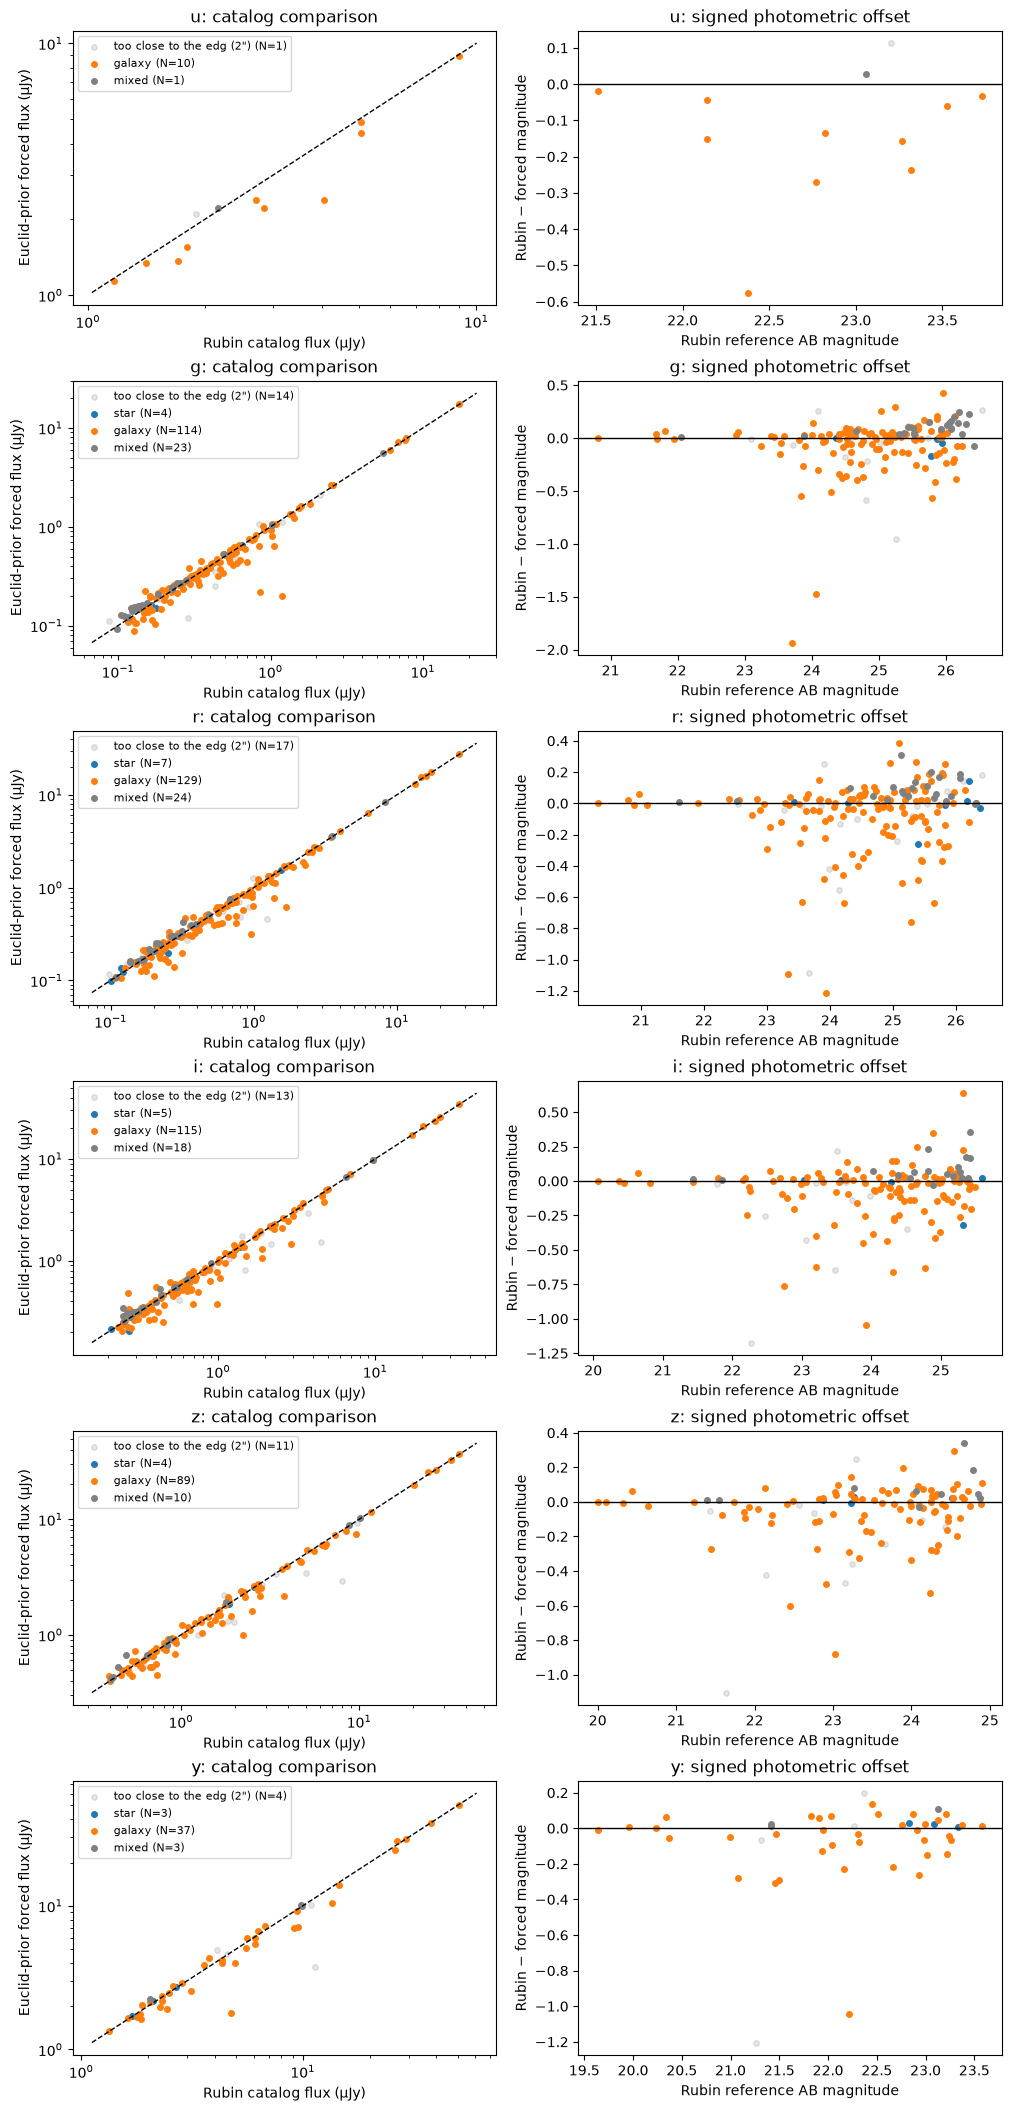

In [15]:
EDGE_cut = 2.0  # Arcsec from the Rubin image edge; changes only the plot marker

# Reference matching is separate from the fits and never changes their fluxes.
comparisons = {}
for band in RUBIN_BANDS:
    image = ground_inputs[band].image
    comparisons[band] = compare_catalog(
        catalog, downloaded[band].catalog, band, max_sep_arcsec=0.5,
        image_wcs=image.wcs, image_shape=image.science_ujy.shape, edge_margin_arcsec=EDGE_cut,
    )
    comparisons[band].write(OUTPUT_DIR / f"{band}_catalog_comparison.ecsv", overwrite=True)

fig = show_catalog_comparisons(comparisons)
#fig.savefig(OUTPUT_DIR / "catalog_comparison.png", dpi=150)
plt.show()
client.close()


## 6. Inspect the sources
Examples of sources with magnitudes agree within 0.1 mag across the selected bands. 

Showing r-band and y-band (INSPECT_BANDS) for examples. 

Good examples: 3 sources in ['r', 'y']
Source -591167871487405687


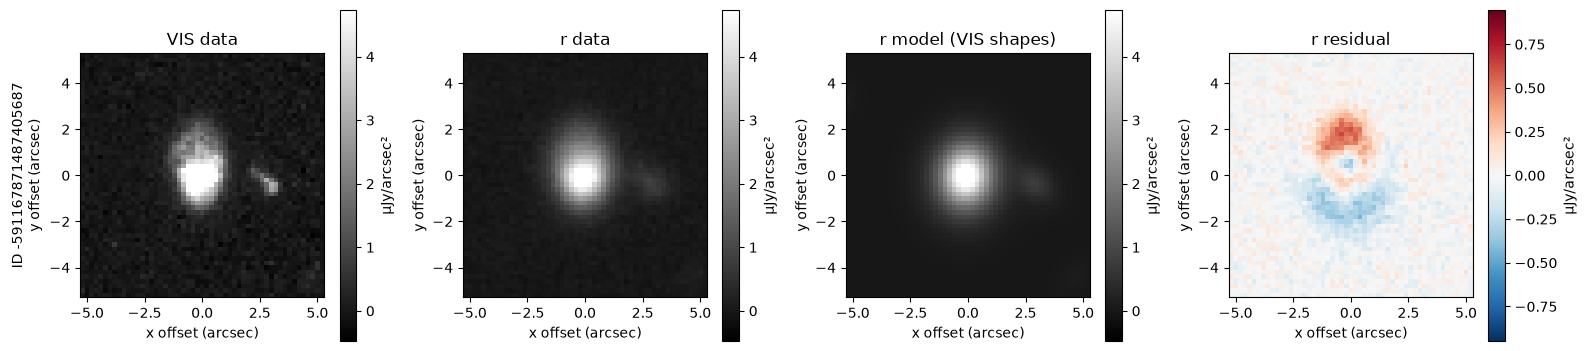

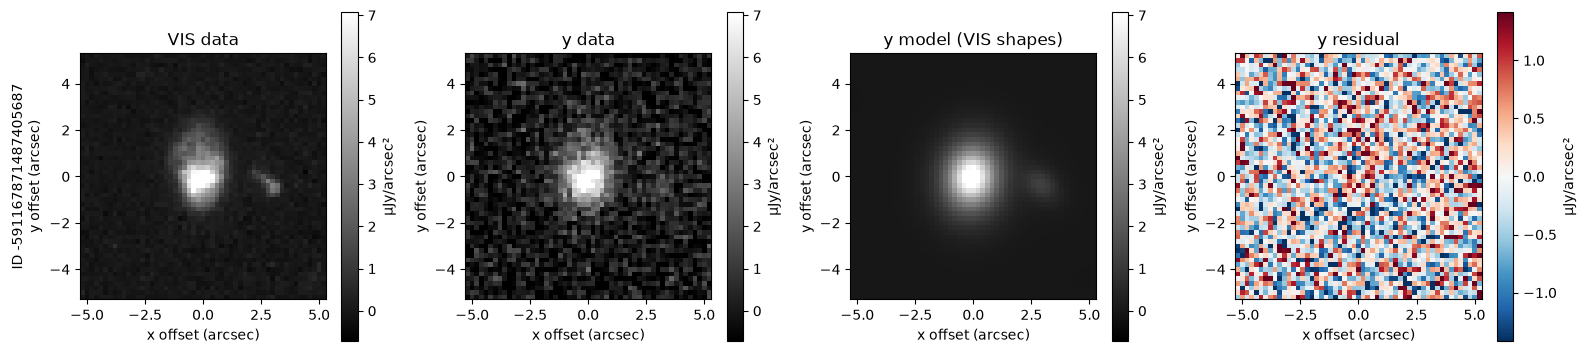

Source -590959707487405972


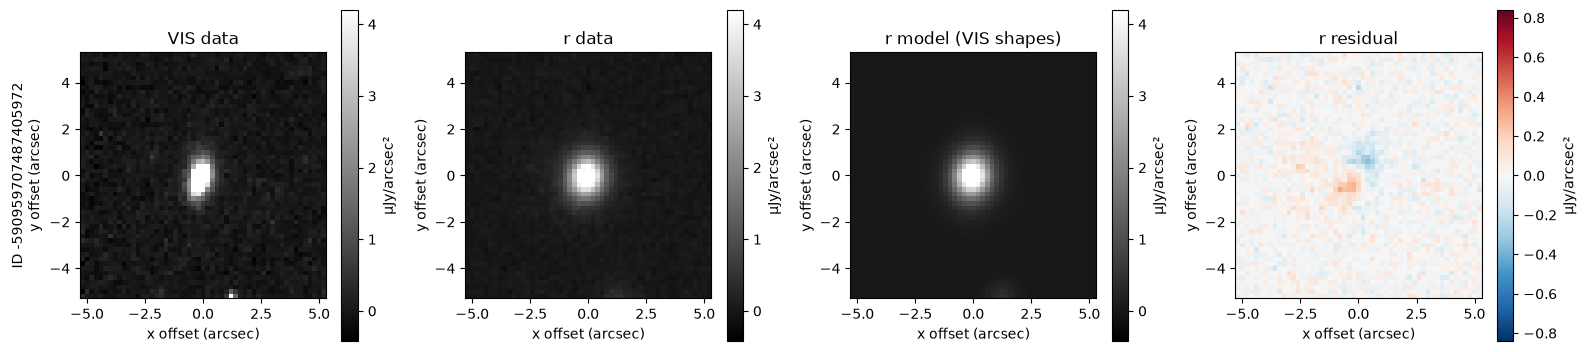

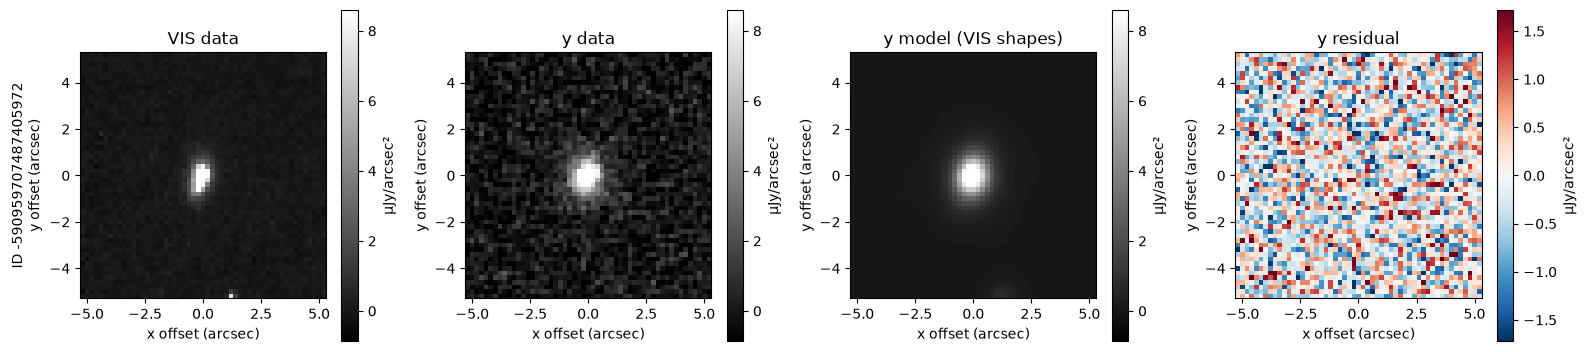

Source -591019829487365524


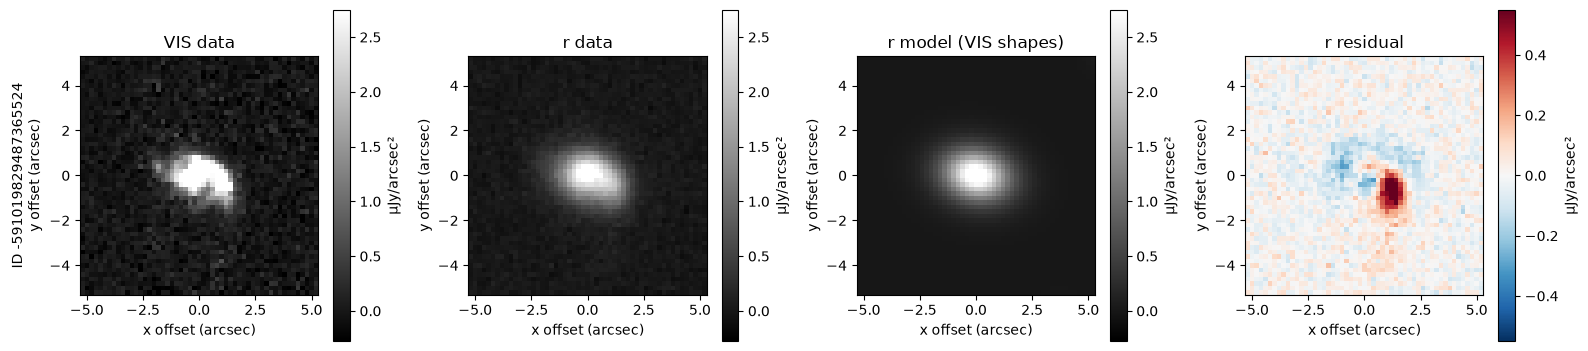

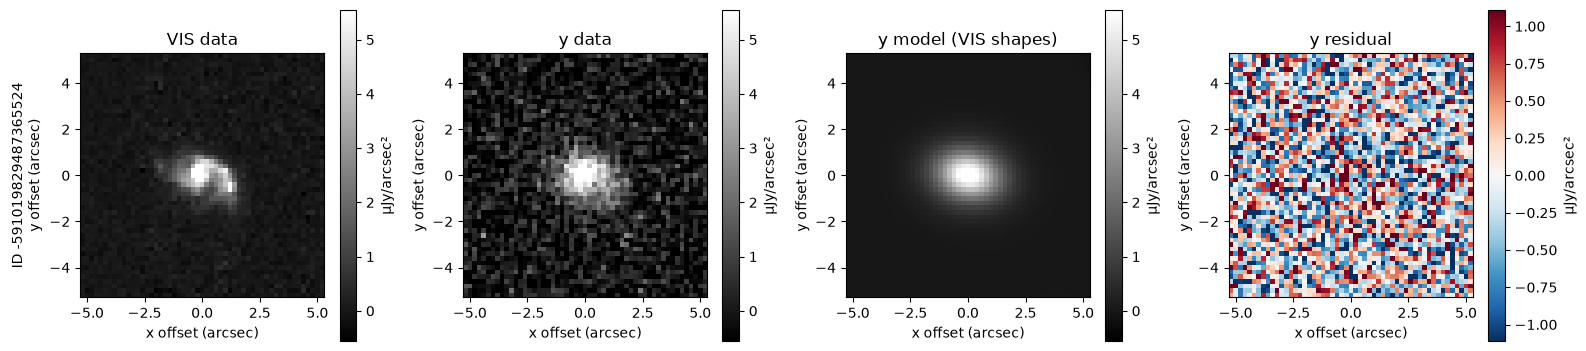

In [16]:
# Three good examples, shown at the same positions in each selected band.
INSPECT_BANDS = ["r", "y"]
N_SOURCES = 3
GOOD_MAX_OFFSET_MAG = 0.1
CUTOUT_SIZE_ARCSEC = 10.0
INSPECT_OBJECT_IDS = None  # Optional list of source IDs, overriding selection
INSPECT_VMIN = None        # µJy/arcsec²
INSPECT_VMAX = None        # µJy/arcsec²

INSPECT_BANDS = [b for b in INSPECT_BANDS
                 if b in RUBIN_BANDS and b in comparisons and b in ground_fits]
if not INSPECT_BANDS:
    print("No selected inspection bands are available in this run.")
else:
    good_scores = {}
    for band in INSPECT_BANDS:
        table = comparisons[band]
        with np.errstate(divide="ignore", invalid="ignore"):
            delta_mag = 2.5 * np.log10(table["forced_flux_ujy"] / table["reference_flux_ujy"])
        good = (np.asarray(table["accepted"], bool) &
                (table["edge_distance_arcsec"] >= max(EDGE_cut, CUTOUT_SIZE_ARCSEC / 2)) &
                (np.abs(delta_mag) < GOOD_MAX_OFFSET_MAG))
        good_scores[band] = {int(row["object_id"]): float(row["forced_flux_ujy"] / row["forced_error_ujy"])
                             for row in table[good]}
    common = set.intersection(*(set(good_scores[b]) for b in INSPECT_BANDS))
    good_ids = sorted(common, key=lambda i: min(good_scores[b][i] for b in INSPECT_BANDS),
                      reverse=True)[:N_SOURCES]
    if INSPECT_OBJECT_IDS is not None:
        good_ids = list(INSPECT_OBJECT_IDS)
    selection = Table({"object_id": np.asarray(good_ids, dtype=np.int64)})
    selection.meta.update({"BANDS": INSPECT_BANDS, "MAX_OFFSET_MAG": GOOD_MAX_OFFSET_MAG})
    selection.write(OUTPUT_DIR / "inspection_good.ecsv", overwrite=True)
    print(f"Good examples: {len(good_ids)} sources in {INSPECT_BANDS}")
    inspection_dir = OUTPUT_DIR / "inspection" / "good"
    inspection_dir.mkdir(parents=True, exist_ok=True)
    for object_id in good_ids:
        print(f"Source {object_id}")
        for band in INSPECT_BANDS:
            fig = gb.show_fit_cutouts(
                ground_fits[band], euclid.vis_cutout, object_ids=[object_id],
                size_arcsec=CUTOUT_SIZE_ARCSEC, vmin=INSPECT_VMIN, vmax=INSPECT_VMAX,
            )
            if fig is not None:
                #fig.savefig(inspection_dir / f"{object_id}_{band}.png", dpi=150)
                plt.show()

Examples of sources where the magnitudes are offset above 0.4 mag. 

Showing r-band and y-band (INSPECT_BANDS) for examples. 

Outliers: 5 sources in ['r', 'y']
Source -591127718487249050


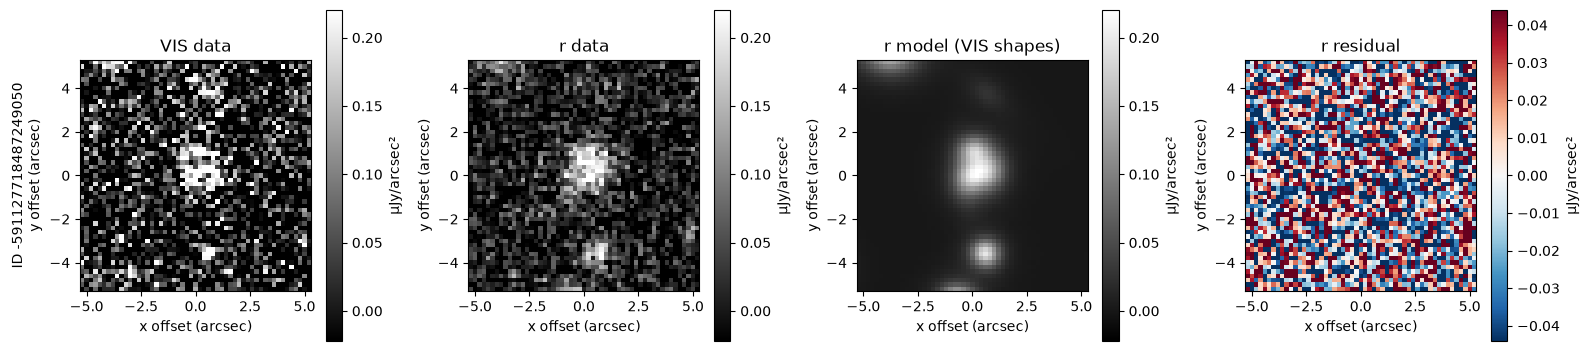

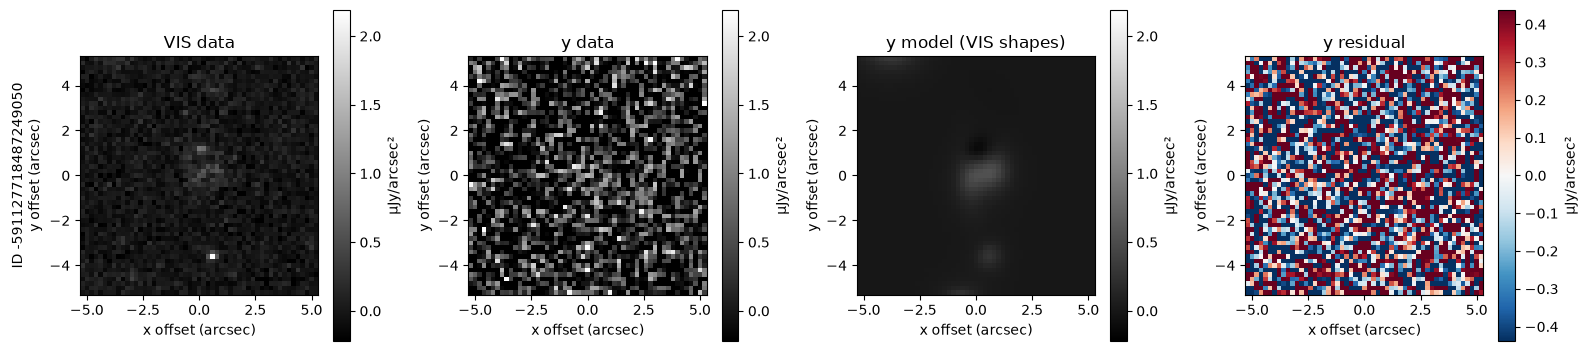

Source -590949474487349992


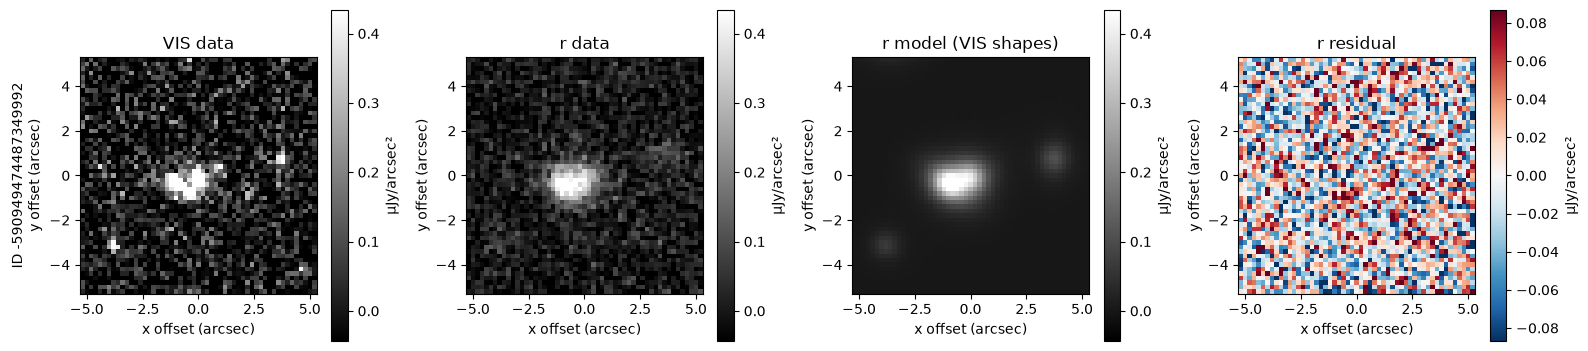

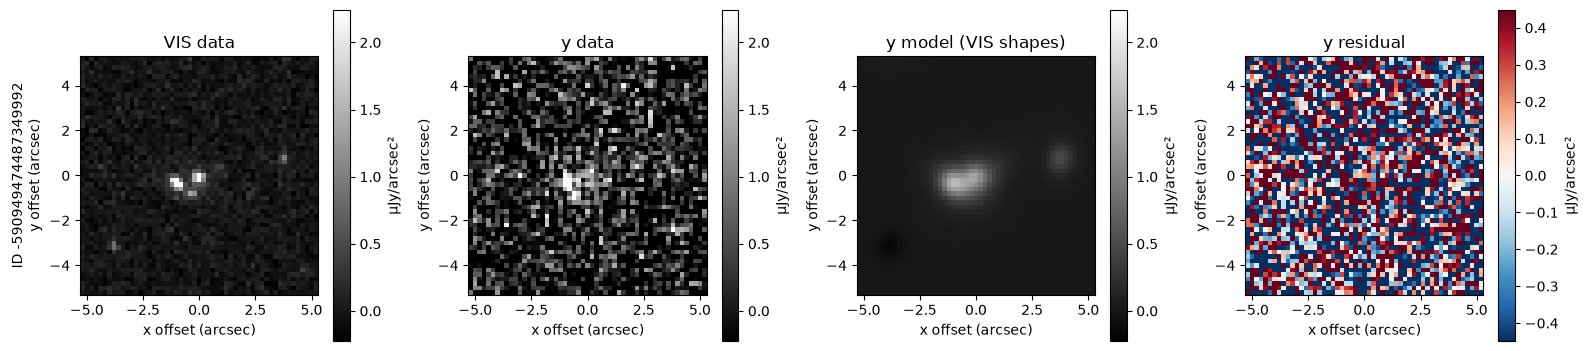

Source -590830380487312128


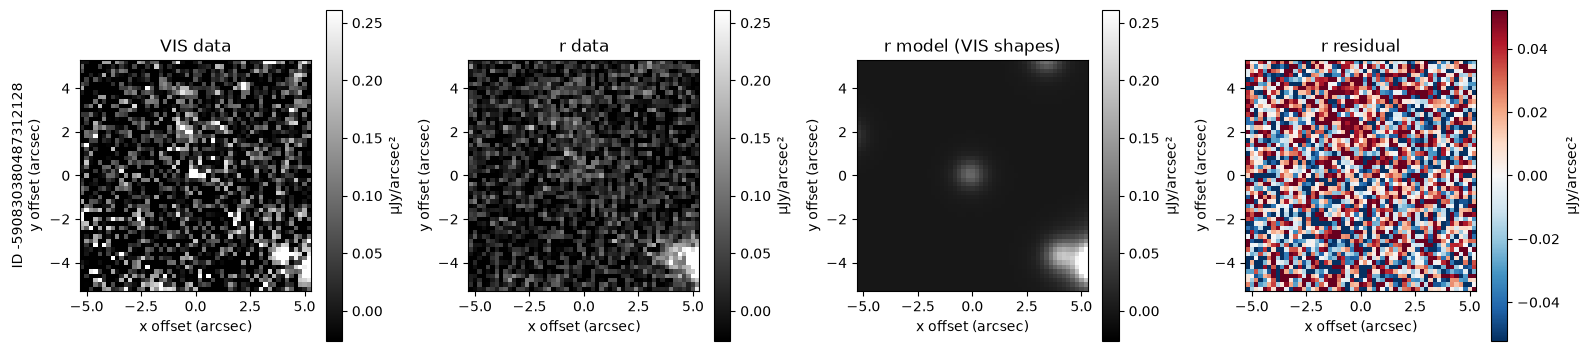

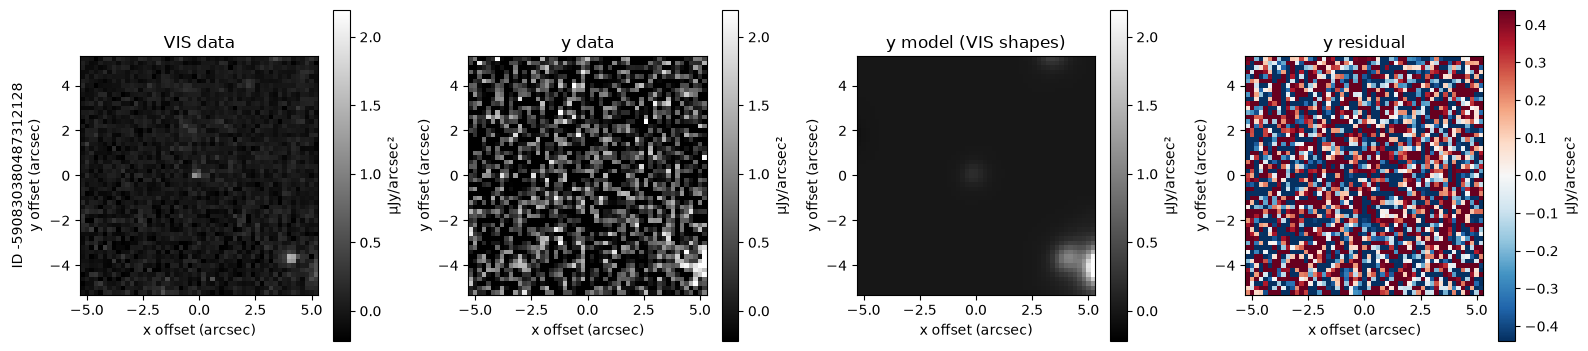

Source -591136098487280755


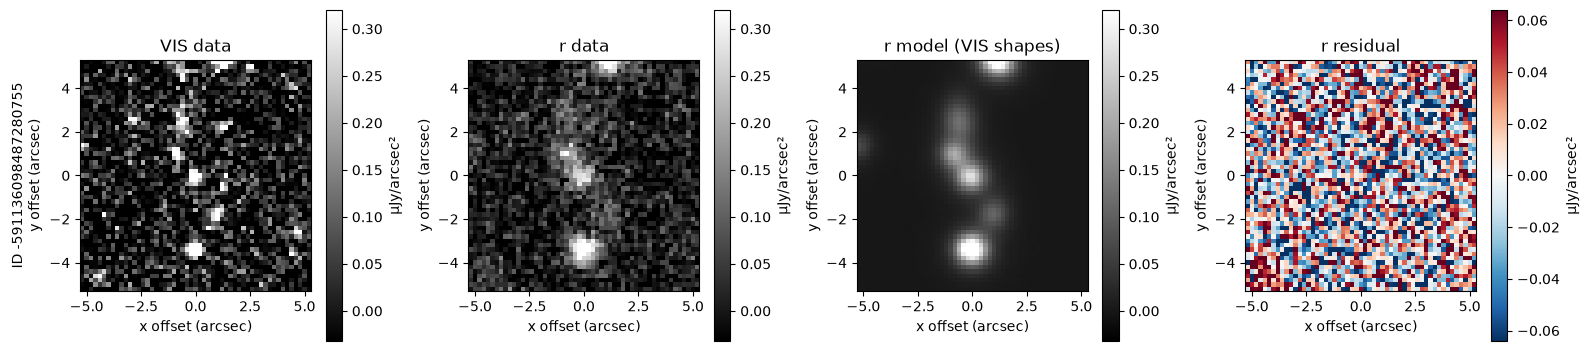

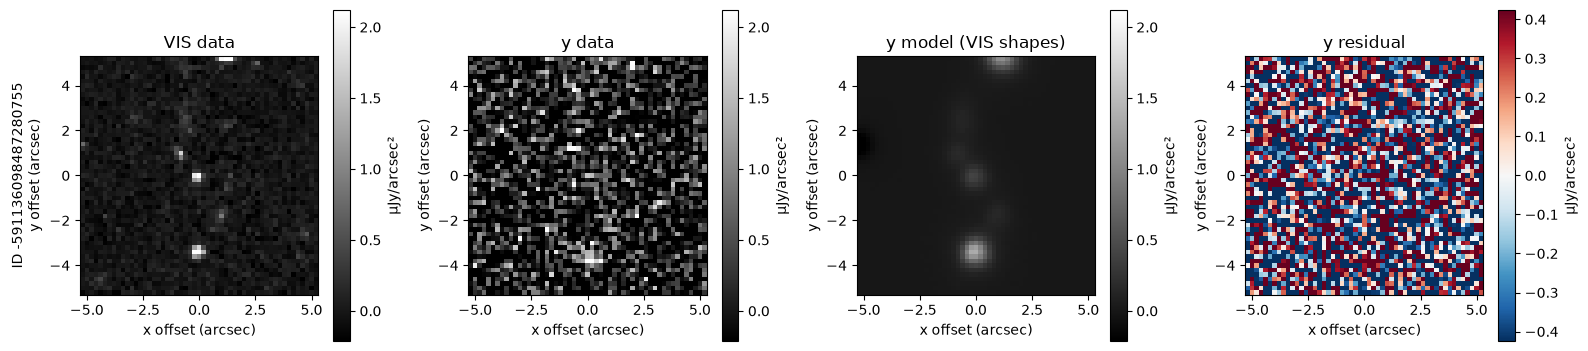

Source -591050384487228674


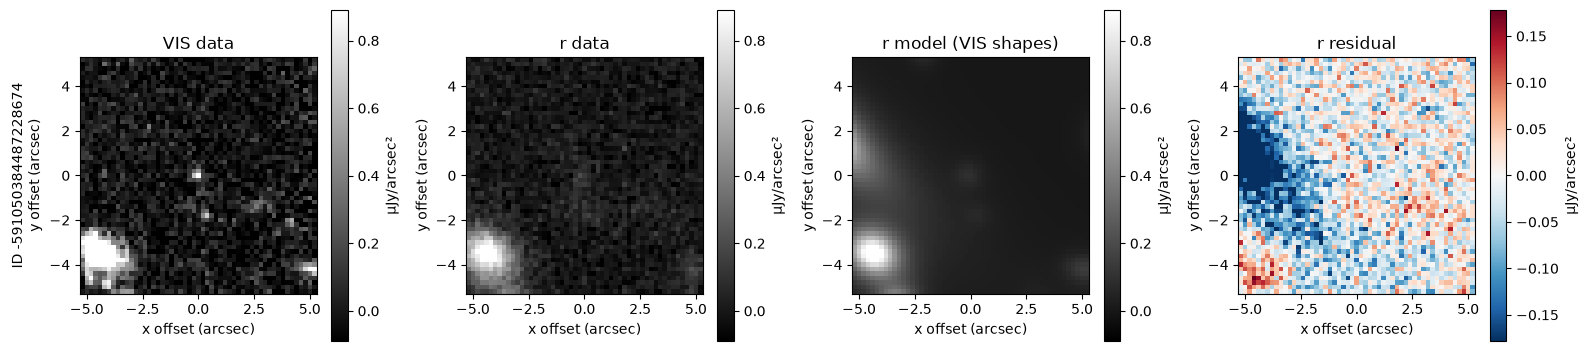

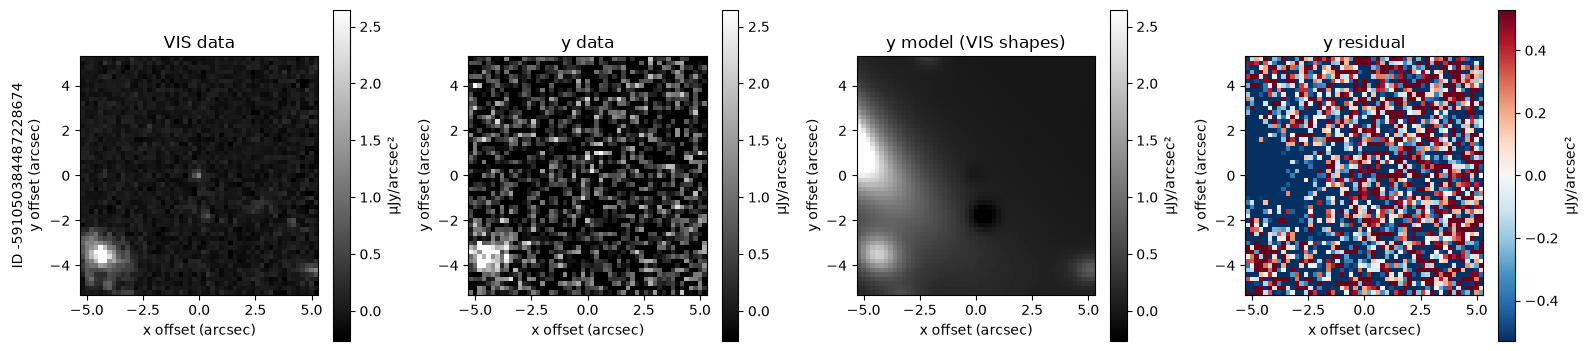

In [17]:
# Five distinct outliers, ranked across these bands and shown in each band.
INSPECT_BANDS = ["r", "y"]
N_SOURCES = 5
OUTLIER_MIN_OFFSET_MAG = 0.4
CUTOUT_SIZE_ARCSEC = 10.0
INSPECT_OBJECT_IDS = None  # Optional list of source IDs, overriding selection
INSPECT_VMIN = None        # µJy/arcsec²
INSPECT_VMAX = None        # µJy/arcsec²

INSPECT_BANDS = [b for b in INSPECT_BANDS
                 if b in RUBIN_BANDS and b in comparisons and b in ground_fits]
if not INSPECT_BANDS:
    print("No selected inspection bands are available in this run.")
else:
    outlier_scores = {}
    for band in INSPECT_BANDS:
        table = comparisons[band]
        with np.errstate(divide="ignore", invalid="ignore"):
            delta_mag = 2.5 * np.log10(table["forced_flux_ujy"] / table["reference_flux_ujy"])
        eligible = (np.asarray(table["accepted"], bool) &
                    ~np.asarray(table["near_image_edge"], bool) &
                    (np.abs(delta_mag) >= OUTLIER_MIN_OFFSET_MAG))
        for row, offset in zip(table[eligible], np.asarray(np.abs(delta_mag))[eligible]):
            object_id = int(row["object_id"])
            outlier_scores[object_id] = max(outlier_scores.get(object_id, 0.), float(offset))
    # Keep IDs present in every selected band's fit for side-by-side inspection.
    common = set.intersection(*(set(map(int, ground_fits[b].catalog["object_id"])) for b in INSPECT_BANDS))
    outlier_ids = sorted((i for i in outlier_scores if i in common),
                         key=outlier_scores.get, reverse=True)[:N_SOURCES]
    if INSPECT_OBJECT_IDS is not None:
        outlier_ids = list(INSPECT_OBJECT_IDS)
    selection = Table({"object_id": np.asarray(outlier_ids, dtype=np.int64),
                       "max_abs_offset_mag": [outlier_scores.get(i, np.nan) for i in outlier_ids]})
    selection.meta.update({"BANDS": INSPECT_BANDS, "MIN_OFFSET_MAG": OUTLIER_MIN_OFFSET_MAG})
    selection.write(OUTPUT_DIR / "inspection_outliers.ecsv", overwrite=True)
    print(f"Outliers: {len(outlier_ids)} sources in {INSPECT_BANDS}")
    inspection_dir = OUTPUT_DIR / "inspection" / "outliers"
    inspection_dir.mkdir(parents=True, exist_ok=True)
    for object_id in outlier_ids:
        print(f"Source {object_id}")
        for band in INSPECT_BANDS:
            fig = gb.show_fit_cutouts(
                ground_fits[band], euclid.vis_cutout, object_ids=[object_id],
                size_arcsec=CUTOUT_SIZE_ARCSEC, vmin=INSPECT_VMIN, vmax=INSPECT_VMAX,
            )
            if fig is not None:
                #fig.savefig(inspection_dir / f"{object_id}_{band}.png", dpi=150)
                plt.show()